# TP noté — Corrigé commenté

Ce notebook reprend les trois exercices du TP noté (séries temporelles, urnes d'Ehrenfest, processus de Poisson).
Chaque question contient **le raisonnement** (en Markdown) puis **le code** qui le met en œuvre.
Les références « Poly » renvoient au polycopié du cours (`Poly.pdf`).

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(7)  # reproductibilité

def acf(x, l):
    n = len(x)
    m = np.mean(x)
    v = np.var(x)
    return np.mean((x[:n-l]-m)*(x[l:]-m))/v

def simuler_poisson(lmbda, T):
    t = 0
    sauts = []
    while t < T:
        t += np.random.exponential(1/lmbda)
        if t < T:
            sauts.append(t)
    return np.array(sauts)

---
## Exercice 1. Prédiction d'une série temporelle

### Question 1 — Import et représentation graphique

n = 200 observations, moyenne = -0.341, variance = 2.398


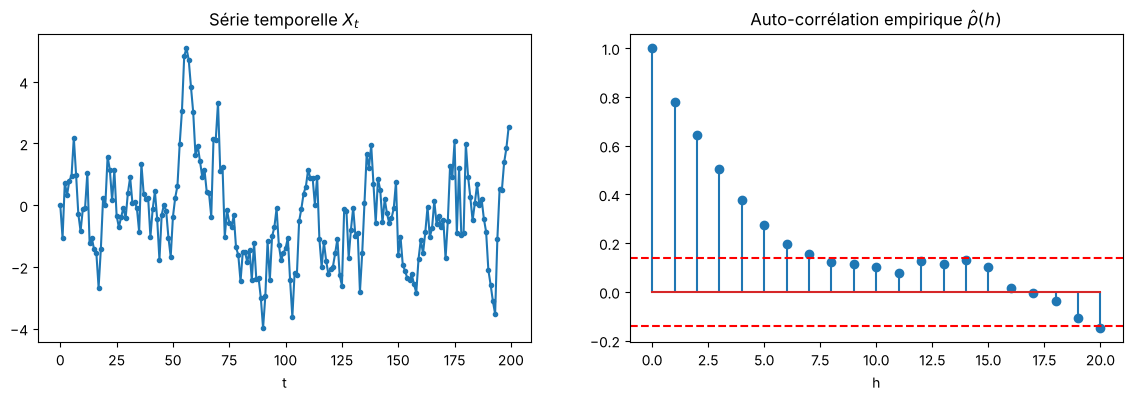

In [2]:
# Le fichier fourni s'appelle "donnees (1).csv" ; on accepte aussi "donnees.csv".
fichier = "donnees.csv" if os.path.exists("donnees.csv") else "donnees (1).csv"
X = np.loadtxt(fichier, delimiter=",")
n = len(X)
print(f"n = {n} observations, moyenne = {X.mean():.3f}, variance = {X.var():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(X, '.-')
ax[0].set_title("Série temporelle $X_t$")
ax[0].set_xlabel("t")
lags = np.arange(0, 21)
ax[1].stem(lags, [1] + [acf(X, l) for l in lags[1:]])
ax[1].axhline(1.96/np.sqrt(n), ls='--', c='r'); ax[1].axhline(-1.96/np.sqrt(n), ls='--', c='r')
ax[1].set_title("Auto-corrélation empirique $\\hat\\rho(h)$")
ax[1].set_xlabel("h")
plt.show()

**Observation.** La série oscille autour d'une moyenne proche de 0, sans tendance ni saisonnalité apparente : l'hypothèse de
stationnarité est raisonnable. L'auto-corrélation empirique décroît **lentement et de façon géométrique**
($\hat\rho(1)\approx 0.78$, $\hat\rho(2)\approx 0.65$, $\hat\rho(3)\approx 0.50$…), ce qui est déjà la signature d'un AR(1).

### Question 2 — Modèle AR(1) : estimation de $\phi$ et prédiction

**Raisonnement (Poly, exercice 2.3).** Pour $X_t=\phi X_{t-1}+\epsilon_t$ stationnaire avec $|\phi|<1$ :

* $\mathbb E[X_t]=\phi\,\mathbb E[X_{t-1}] \Rightarrow \mathbb E[X_t](1-\phi)=0 \Rightarrow \mathbb E[X_t]=0$ ;
* en multipliant par $X_{t-h}$ et en prenant l'espérance ($\epsilon_t$ indépendant du passé) :
  $\gamma(h)=\phi\,\gamma(h-1)$, donc $\rho(h)=\phi^h$. En particulier $\rho(1)=\phi$.

**Estimateur (méthode des moments) :** $\hat\phi=\hat\rho(1)$.

**Prédiction :** la meilleure prédiction (au sens $L^2$) de $X_{n+1}$ sachant le passé est
$\mathbb E[X_{n+1}\mid X_n,\dots]=\phi X_n+\mathbb E[\epsilon_{n+1}]=\phi X_n$, d'où $\hat X_{n+1}=\hat\phi\,X_n$.

*(Remarque : la moyenne empirique vaut $\approx -0.34$, non significativement différente de 0 vu la forte corrélation ;
on garde le modèle centré du cours.)*

In [3]:
phi_hat = acf(X, 1)
X_next_AR = phi_hat * X[-1]
print(f"phi_hat = rho_hat(1) = {phi_hat:.4f}")
print(f"Dernière valeur X_n = {X[-1]:.4f}")
print(f"Prédiction AR(1) de X_(n+1) = phi_hat * X_n = {X_next_AR:.4f}")

# Vérification : rho(h) théorique = phi^h  vs  rho_hat(h)
for h in range(1, 6):
    print(f"h={h}:  rho_hat = {acf(X,h):.3f}   phi_hat^h = {phi_hat**h:.3f}")

phi_hat = rho_hat(1) = 0.7776
Dernière valeur X_n = 2.5334
Prédiction AR(1) de X_(n+1) = phi_hat * X_n = 1.9701
h=1:  rho_hat = 0.778   phi_hat^h = 0.778
h=2:  rho_hat = 0.645   phi_hat^h = 0.605
h=3:  rho_hat = 0.503   phi_hat^h = 0.470
h=4:  rho_hat = 0.376   phi_hat^h = 0.366
h=5:  rho_hat = 0.276   phi_hat^h = 0.284


La décroissance $\hat\rho(h)\approx\hat\phi^h$ est bien vérifiée, ce qui conforte l'hypothèse AR(1).

### Question 3 — Comparaison prédiction / réalité sur les 50 derniers points

**Démarche.** Pour évaluer honnêtement le modèle, on estime $\phi$ **uniquement sur les 150 premiers points**
(échantillon d'apprentissage), puis pour chaque $t$ parmi les 50 derniers on prédit $X_t$ par $\hat X_t=\hat\phi X_{t-1}$
(prédiction à un pas, qui n'utilise que les observations passées). On mesure l'erreur par l'erreur quadratique moyenne
$\text{EQM}=\frac1{50}\sum_t (X_t-\hat X_t)^2$.

Valeur théorique attendue : l'erreur de prédiction est $X_{t}-\phi X_{t-1}=\epsilon_t$, donc l'EQM doit être proche de
$\sigma^2=\gamma(0)(1-\phi^2)$ (car $\gamma(0)=\sigma^2/(1-\phi^2)$ pour un AR(1)).

phi estimé sur les 150 premiers points : 0.8086
EQM AR(1) sur les 50 derniers points : 1.1241  (RMSE = 1.0602)
Variance théorique du bruit sigma^2 = gamma(0)(1-phi^2) ≈ 0.8607
À titre de comparaison, prédire 0 (la moyenne) donne une EQM de 2.4124


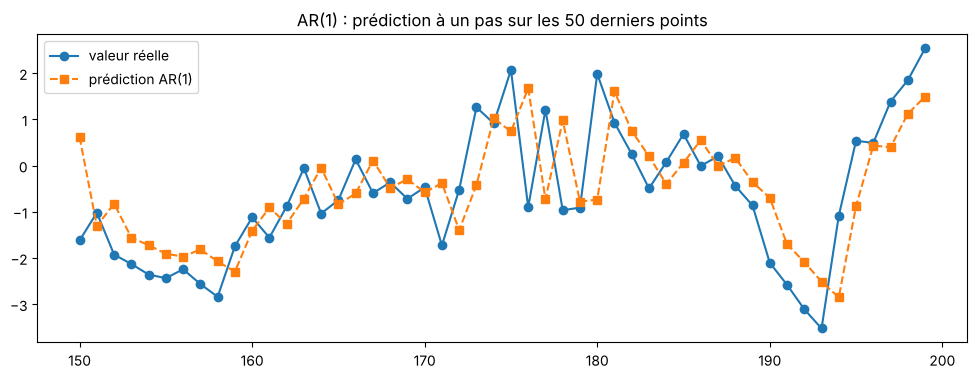

In [4]:
n_test = 50
n_train = n - n_test
phi_train = acf(X[:n_train], 1)

idx = np.arange(n_train, n)                 # instants à prédire
pred_AR = phi_train * X[idx - 1]             # prédiction à un pas
err_AR = X[idx] - pred_AR
eqm_AR = np.mean(err_AR**2)
sigma2_theo = np.var(X[:n_train]) * (1 - phi_train**2)

print(f"phi estimé sur les {n_train} premiers points : {phi_train:.4f}")
print(f"EQM AR(1) sur les 50 derniers points : {eqm_AR:.4f}  (RMSE = {np.sqrt(eqm_AR):.4f})")
print(f"Variance théorique du bruit sigma^2 = gamma(0)(1-phi^2) ≈ {sigma2_theo:.4f}")
print(f"À titre de comparaison, prédire 0 (la moyenne) donne une EQM de {np.mean(X[idx]**2):.4f}")

plt.figure(figsize=(12, 4))
plt.plot(idx, X[idx], 'o-', label="valeur réelle")
plt.plot(idx, pred_AR, 's--', label="prédiction AR(1)")
plt.title("AR(1) : prédiction à un pas sur les 50 derniers points")
plt.legend(); plt.show()

L'EQM obtenue est du même ordre que la variance du bruit $\sigma^2$ : c'est l'erreur minimale atteignable, puisque
$\epsilon_{t}$ est imprévisible. Le modèle AR(1) fait bien mieux qu'une prédiction naïve par la moyenne.

### Question 4 — Modèle MA(1)

**Raisonnement (Poly, exercice 2.2).** Pour $X_t=\epsilon_t-\theta\epsilon_{t-1}$, $|\theta|<1$ :

* $\mathbb E[X_t]=0$, $\gamma(0)=\sigma^2(1+\theta^2)$, $\gamma(1)=-\theta\sigma^2$, $\gamma(h)=0$ pour $h\ge2$.
* Donc $\rho(1)=\dfrac{-\theta}{1+\theta^2}$ et $\rho(h)=0$ pour $h\ge 2$.

**Estimateur de $\theta$ (moments).** On résout $\hat\rho(1)(1+\theta^2)+\theta=0$, i.e.
$\hat\rho\,\theta^2+\theta+\hat\rho=0$, dont la racine de module $<1$ est
$$\hat\theta=\frac{-1+\sqrt{1-4\hat\rho(1)^2}}{2\hat\rho(1)}.$$
⚠️ Cette racine n'existe que si $|\hat\rho(1)|\le 1/2$ : en effet $\left|\frac{\theta}{1+\theta^2}\right|\le\frac12$ pour tout $\theta$.
**Un MA(1) ne peut jamais avoir une auto-corrélation d'ordre 1 supérieure à 1/2 en valeur absolue.**

**Prédiction.** D'après la question 2 de l'ex. 2.2, $\epsilon_t=\sum_{k\ge0}\theta^kX_{t-k}$ (inversibilité, $|\theta|<1$).
On reconstruit donc les bruits récursivement : $\hat\epsilon_t=X_t+\theta\hat\epsilon_{t-1}$ (avec $\hat\epsilon_0=0$) et
$$\hat X_{n+1}=\mathbb E[\epsilon_{n+1}]-\theta\hat\epsilon_n=-\theta\,\hat\epsilon_n .$$

In [5]:
rho1 = acf(X, 1)
print(f"rho_hat(1) = {rho1:.4f}")
if abs(rho1) <= 0.5:
    theta_mom = (-1 + np.sqrt(1 - 4*rho1**2)) / (2*rho1)
    print(f"theta (moments) = {theta_mom:.4f}")
else:
    print("|rho_hat(1)| > 1/2 : l'équation n'a pas de solution réelle -> la méthode des moments échoue.")
    print("C'est déjà un argument fort CONTRE le modèle MA(1).")

rho_hat(1) = 0.7776
|rho_hat(1)| > 1/2 : l'équation n'a pas de solution réelle -> la méthode des moments échoue.
C'est déjà un argument fort CONTRE le modèle MA(1).


Comme $\hat\rho(1)\approx0.78>1/2$, la méthode des moments n'a pas de solution. Pour pouvoir quand même comparer
les deux modèles, on estime $\theta$ par **moindres carrés conditionnels** : on choisit le $\theta\in]-1;1[$ qui minimise
la somme des carrés des bruits reconstruits $\sum_t\hat\epsilon_t(\theta)^2$ sur la partie apprentissage
(c'est la méthode standard d'estimation d'un MA). On effectue ensuite les mêmes prédictions à un pas sur les 50 derniers points.

theta (moindres carrés conditionnels) = -0.6050
rho(1) impliqué par ce theta : 0.443  (contre rho_hat(1) = 0.778)
Prédiction MA(1) de X_(n+1) = -theta * eps_n = 1.1302

EQM AR(1) = 1.1241
EQM MA(1) = 1.5462


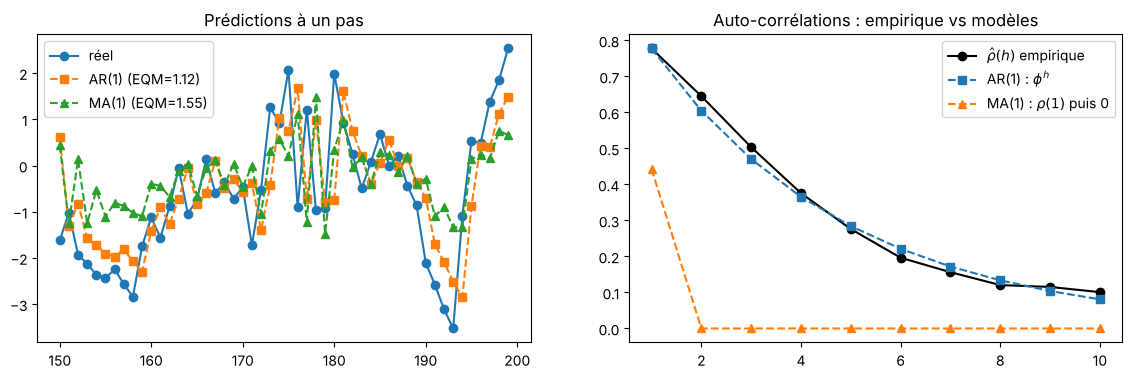

In [6]:
def residus_MA(x, theta):
    eps = np.zeros(len(x))
    for t in range(len(x)):
        eps[t] = x[t] + theta * (eps[t-1] if t > 0 else 0.0)
    return eps

grille = np.linspace(-0.99, 0.99, 397)
sse = [np.sum(residus_MA(X[:n_train], th)**2) for th in grille]
theta_hat = grille[np.argmin(sse)]
print(f"theta (moindres carrés conditionnels) = {theta_hat:.4f}")
print(f"rho(1) impliqué par ce theta : {-theta_hat/(1+theta_hat**2):.3f}  (contre rho_hat(1) = {rho1:.3f})")

# Prédiction de la valeur suivante X_(n+1) avec toute la série
eps_all = residus_MA(X, theta_hat)
print(f"Prédiction MA(1) de X_(n+1) = -theta * eps_n = {-theta_hat*eps_all[-1]:.4f}")

# Prédictions à un pas sur les 50 derniers points (les résidus en t-1 n'utilisent que X_1..X_{t-1})
pred_MA = -theta_hat * eps_all[idx - 1]
err_MA = X[idx] - pred_MA
eqm_MA = np.mean(err_MA**2)

print(f"\nEQM AR(1) = {eqm_AR:.4f}")
print(f"EQM MA(1) = {eqm_MA:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(idx, X[idx], 'o-', label="réel")
ax[0].plot(idx, pred_AR, 's--', label=f"AR(1) (EQM={eqm_AR:.2f})")
ax[0].plot(idx, pred_MA, '^--', label=f"MA(1) (EQM={eqm_MA:.2f})")
ax[0].legend(); ax[0].set_title("Prédictions à un pas")
h = np.arange(1, 11)
ax[1].plot(h, [acf(X, l) for l in h], 'ko-', label="$\\hat\\rho(h)$ empirique")
ax[1].plot(h, phi_hat**h, 's--', label="AR(1) : $\\phi^h$")
ax[1].plot(h, [-theta_hat/(1+theta_hat**2)] + [0]*9, '^--', label="MA(1) : $\\rho(1)$ puis 0")
ax[1].legend(); ax[1].set_title("Auto-corrélations : empirique vs modèles")
plt.show()

**Conclusion : le modèle AR(1) est clairement le plus adapté.**

1. *Argument théorique* : un MA(1) a $|\rho(1)|\le 1/2$ et $\rho(h)=0$ pour $h\ge2$. Or ici $\hat\rho(1)\approx0.78$ et les
   auto-corrélations restent significatives (au-dessus de la bande $\pm1.96/\sqrt n$) jusqu'à $h\approx 5$-$6$,
   avec une décroissance géométrique $\hat\rho(h)\approx\hat\phi^h$ : c'est exactement le profil d'un AR(1).
2. *Argument empirique* : l'erreur de prédiction à un pas sur les 50 derniers points est nettement plus faible avec l'AR(1)
   (proche de la variance du bruit, donc quasi optimale) qu'avec le MA(1).

---
## Exercice 2. Urnes d'Ehrenfest

### Question 1 — Simulation

**Modélisation.** Si $X_t=x$ boules sont dans $A$, on tire une boule uniformément parmi $N$ :
* avec probabilité $x/N$ elle vient de $A$ et passe dans $B$ : $X_{t+1}=x-1$ ;
* avec probabilité $(N-x)/N$ elle vient de $B$ et passe dans $A$ : $X_{t+1}=x+1$.

$(X_t)$ est donc une chaîne de Markov sur $\{0,\dots,N\}$ de transitions $P(x,x-1)=x/N$, $P(x,x+1)=1-x/N$.
Pour simuler fidèlement l'expérience, on tire réellement une boule (numéro uniforme dans $\{0,\dots,N-1\}$) et on regarde
dans quelle urne elle se trouve.

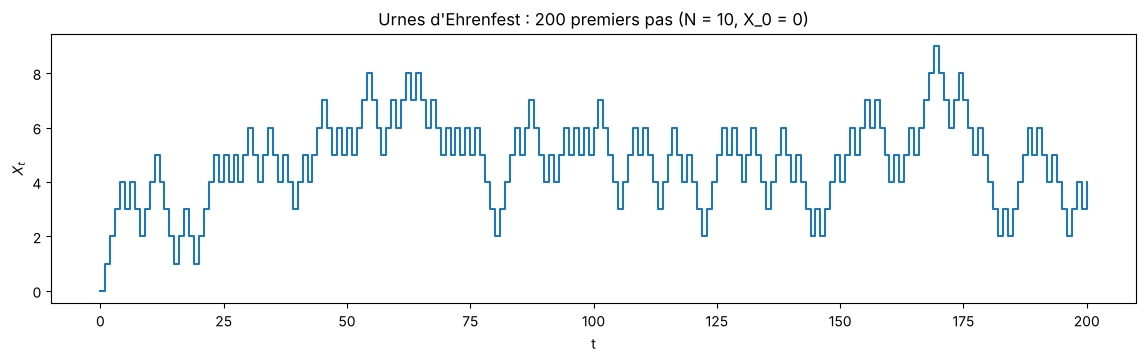

In [7]:
def ehrenfest(N, n, x0=0):
    # dans_A[i] = True si la boule i est dans l'urne A
    dans_A = np.zeros(N, dtype=bool)
    dans_A[:x0] = True
    X = np.empty(n + 1, dtype=int)
    X[0] = x0
    tirages = np.random.randint(0, N, size=n)
    for t in range(n):
        b = tirages[t]
        dans_A[b] = not dans_A[b]        # la boule tirée change d'urne
        X[t+1] = dans_A.sum()
    return X

N, n = 10, 10000
traj = ehrenfest(N, n)

plt.figure(figsize=(14, 3.5))
plt.step(np.arange(201), traj[:201], where='post')
plt.title("Urnes d'Ehrenfest : 200 premiers pas (N = 10, X_0 = 0)")
plt.xlabel("t"); plt.ylabel("$X_t$"); plt.show()

Partant de $X_0=0$, la trajectoire remonte rapidement vers $N/2=5$ puis fluctue autour de cette valeur
(le rappel vers le centre vient de ce qu'il est plus probable de retirer une boule de l'urne la plus remplie).

### Question 2 — Ergodicité

**Rappel.** La chaîne est irréductible sur un espace fini, donc elle admet une unique loi invariante $\pi$ et le
théorème ergodique donne, pour tout état $x$ :
$$\frac1n\sum_{t=1}^{n}\mathbf 1_{\{X_t=x\}}\xrightarrow[n\to\infty]{p.s.}\pi(x).$$

**Vérification que $\pi=\mathcal B(N,1/2)$** : on vérifie l'équilibre détaillé $\pi(x)P(x,x+1)=\pi(x+1)P(x+1,x)$ :
$$\binom Nx 2^{-N}\frac{N-x}{N}=\binom N{x+1}2^{-N}\frac{x+1}{N}
\iff \frac{N!}{x!(N-x-1)!}=\frac{N!}{x!(N-x-1)!}\ \checkmark$$
La chaîne est réversible par rapport à $\pi$, donc $\pi$ est invariante.

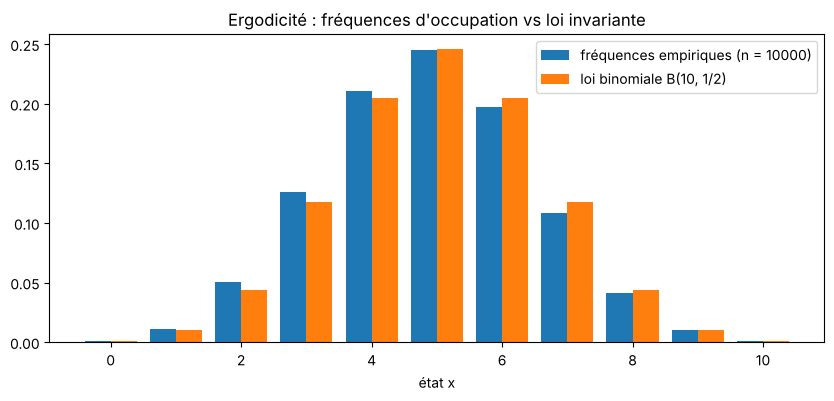

 x   fréquence    pi(x)
 0   0.0006     0.0010
 1   0.0109     0.0098
 2   0.0504     0.0439
 3   0.1262     0.1172
 4   0.2103     0.2051
 5   0.2449     0.2461
 6   0.1969     0.2051
 7   0.1079     0.1172
 8   0.0409     0.0439
 9   0.0101     0.0098
10   0.0009     0.0010

Distance en variation totale : 0.0222


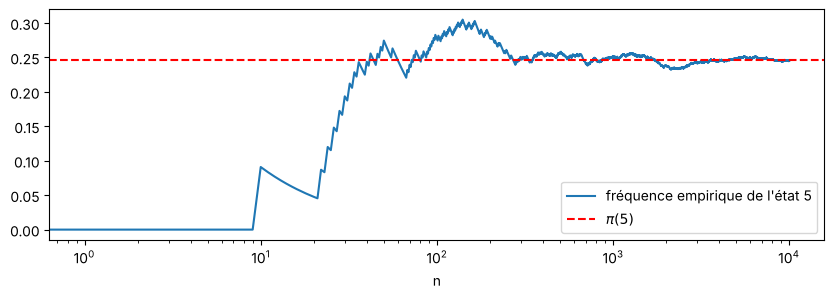

In [8]:
etats = np.arange(N + 1)
freq = np.array([np.mean(traj[1:] == x) for x in etats])
pi = stats.binom.pmf(etats, N, 0.5)

w = 0.4
plt.figure(figsize=(10, 4))
plt.bar(etats - w/2, freq, w, label="fréquences empiriques (n = 10000)")
plt.bar(etats + w/2, pi, w, label="loi binomiale B(10, 1/2)")
plt.xlabel("état x"); plt.legend(); plt.title("Ergodicité : fréquences d'occupation vs loi invariante")
plt.show()

print(" x   fréquence    pi(x)")
for x in etats:
    print(f"{x:2d}   {freq[x]:.4f}     {pi[x]:.4f}")
print(f"\nDistance en variation totale : {0.5*np.abs(freq-pi).sum():.4f}")

# Convergence des fréquences quand n grandit (état x = 5)
cum = np.cumsum(traj[1:] == 5) / np.arange(1, n + 1)
plt.figure(figsize=(10, 3))
plt.plot(cum, label="fréquence empirique de l'état 5")
plt.axhline(pi[5], c='r', ls='--', label="$\\pi(5)$")
plt.xscale('log'); plt.legend(); plt.xlabel("n"); plt.show()

Les fréquences empiriques sont très proches des probabilités binomiales (distance en variation totale de l'ordre
de quelques $10^{-2}$), et la fréquence d'occupation de chaque état converge vers $\pi(x)$ quand $n$ augmente :
**la propriété d'ergodicité est validée empiriquement**.

### Question 3 — Convergence en loi ?

**Réponse : non.** La chaîne est **périodique de période 2** : à chaque pas, $X_t$ change de $\pm1$, donc la parité de
$X_t$ alterne. Comme $X_0=0$ :
$$X_t \text{ est pair si } t \text{ est pair}, \qquad X_t \text{ est impair si } t \text{ est impair.}$$
Ainsi $\mathbb P(X_t \text{ pair})$ vaut alternativement 1 et 0 : la loi de $X_t$ ne peut pas converger vers $\pi$
(ni vers aucune loi). Le théorème de convergence en loi des chaînes de Markov exige l'**apériodicité**, ce qui n'est pas le cas
ici (alors que le théorème ergodique, lui, ne la demande pas — d'où la question 2).

En revanche, les sous-suites convergent : $X_{2t}\to \pi_{\text{pair}}$ où $\pi_{\text{pair}}(x)=2\pi(x)$ pour $x$ pair,
et $X_{2t+1}\to\pi_{\text{impair}}(x)=2\pi(x)$ pour $x$ impair (car $\sum_{x \text{ pair}}\pi(x)=1/2$).

On le vérifie en simulant $M$ trajectoires indépendantes et en regardant la loi empirique de $X_t$ à $t=1000$ et $t=1001$.

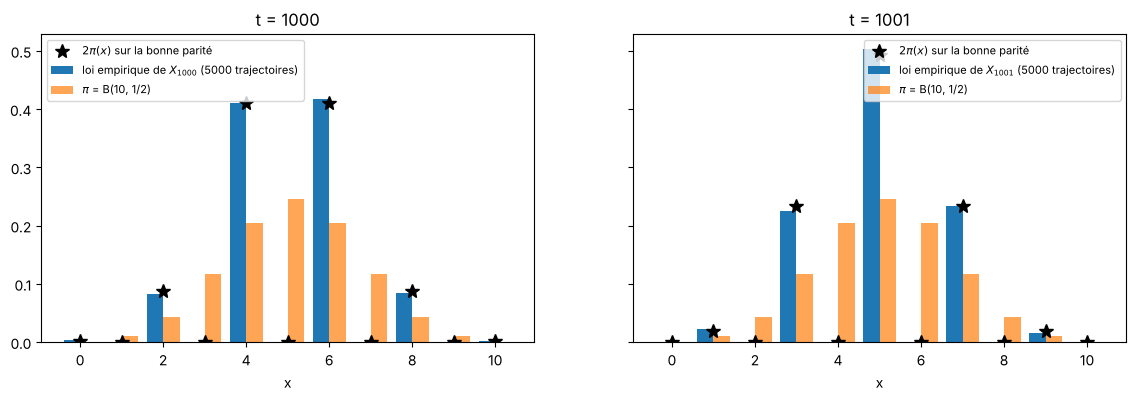

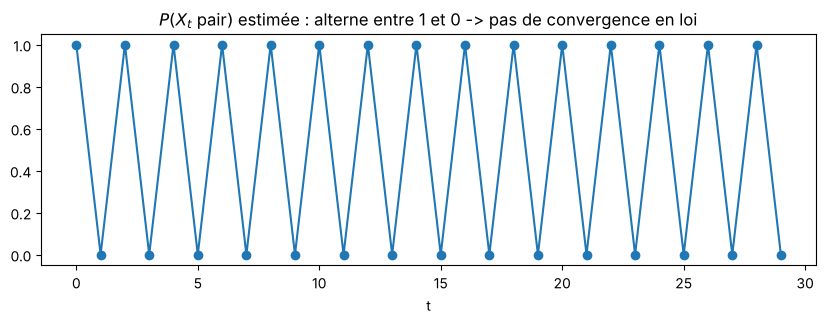

In [9]:
M = 5000
T1 = 1001
trajs = np.array([ehrenfest(N, T1) for _ in range(M)])

fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for a, t in zip(ax, [1000, 1001]):
    loi_emp = np.array([np.mean(trajs[:, t] == x) for x in etats])
    a.bar(etats - w/2, loi_emp, w, label=f"loi empirique de $X_{{{t}}}$ ({M} trajectoires)")
    a.bar(etats + w/2, pi, w, label="$\\pi$ = B(10, 1/2)", alpha=0.7)
    a.plot(etats, 2*pi*((etats % 2) == (t % 2)), 'k*', ms=10, label="$2\\pi(x)$ sur la bonne parité")
    a.set_title(f"t = {t}"); a.legend(fontsize=8); a.set_xlabel("x")
plt.show()

p_pair = np.mean(trajs % 2 == 0, axis=0)
plt.figure(figsize=(10, 3))
plt.plot(np.arange(30), p_pair[:30], 'o-')
plt.title("$P(X_t$ pair$)$ estimée : alterne entre 1 et 0 -> pas de convergence en loi")
plt.xlabel("t"); plt.show()

La loi de $X_{1000}$ est concentrée sur les états pairs, celle de $X_{1001}$ sur les états impairs : la loi de $X_t$
oscille et **ne converge pas** quand $t\to\infty$. (Une version « paresseuse » de la chaîne, où l'on ne fait rien avec
probabilité $1/2$, serait apériodique et convergerait en loi vers $\mathcal B(N,1/2)$.)

---
## Exercice 3. Processus de Poisson (bus)

### Question 1 — Simulation d'une journée

Il passe en moyenne 3 bus par heure. Pour un processus de Poisson d'intensité $\lambda$, $\mathbb E[N_t]=\lambda t$, donc
$\lambda = 3$ bus/heure (temps en heures). La journée de service dure de 8h à 17h, soit $T=9$ heures ; on compte le temps
à partir de 8h. Les temps inter-passages sont i.i.d. $\mathcal E(\lambda)$, de moyenne $1/\lambda=20$ minutes.
En moyenne on attend $\lambda T=27$ bus dans la journée.

Nombre de bus dans la journée : 29 (espérance lambda*T = 27)
Horaires de passage :
8h01, 8h30, 8h34, 8h51, 9h44, 10h06, 10h12, 10h55, 11h13, 11h19, 12h32, 12h43, 12h59, 13h45, 14h23, 14h37, 14h55, 15h04, 15h09, 15h25, 15h27, 15h28, 15h37, 15h52, 16h03, 16h09, 16h18, 16h23, 16h38


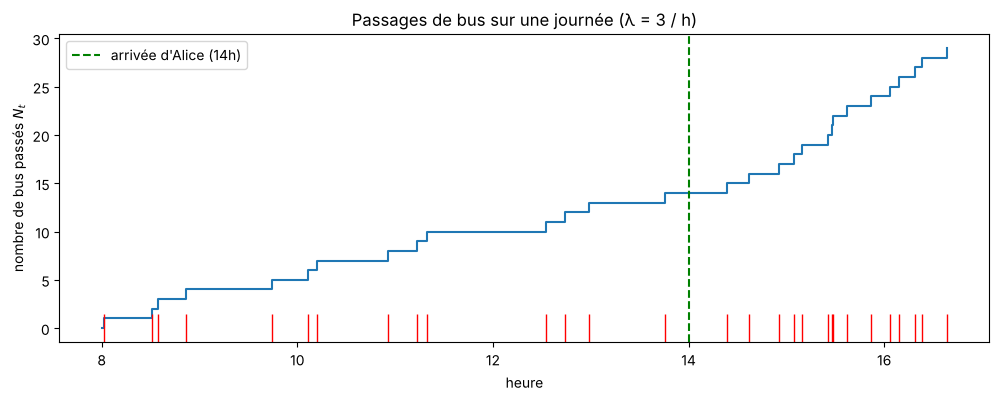

In [10]:
lam = 3.0       # bus par heure
T = 9.0         # 8h -> 17h
debut = 8.0

sauts = simuler_poisson(lam, T)
print(f"Nombre de bus dans la journée : {len(sauts)} (espérance lambda*T = {lam*T:.0f})")
print("Horaires de passage :")
minutes = (debut*60 + sauts*60).astype(int)
print(", ".join(f"{m // 60}h{m % 60:02d}" for m in minutes))

N_t = np.concatenate(([0], np.arange(1, len(sauts) + 1)))
plt.figure(figsize=(12, 4))
plt.step(np.concatenate(([0], sauts)) + debut, N_t, where='post')
plt.plot(sauts + debut, np.zeros_like(sauts), '|', ms=20, c='r')
plt.axvline(14, c='g', ls='--', label="arrivée d'Alice (14h)")
plt.xlabel("heure"); plt.ylabel("nombre de bus passés $N_t$")
plt.title("Passages de bus sur une journée (λ = 3 / h)")
plt.legend(); plt.show()

### Questions 2 et 3 — Temps $X$ depuis le dernier bus et temps d'attente $Y$ à 14h

Alice arrive à $t_0=14\text{h}$, soit $t_0=6$ heures après le début. Si $T_{k}$ désigne le dernier passage avant $t_0$
et $T_{k+1}$ le suivant :
$$X = t_0 - T_k,\qquad Y = T_{k+1}-t_0 .$$
(L'énoncé écrit $Y_n, Z_n$ : il s'agit des réalisations journalières $X_n, Y_n$, $n=1,\dots,1000$.)

**Ce que dit la théorie (Poly, « propriétés remarquables »).**
* $Y\sim\mathcal E(\lambda)$ : par absence de mémoire de la loi exponentielle (propriété de Markov forte), le processus
  redémarre en $t_0$ comme un processus de Poisson neuf.
* $X\sim\mathcal E(\lambda)$ (à une troncature près) : $\mathbb P(X>x)=\mathbb P(\text{aucun bus dans }]t_0-x,t_0])=e^{-\lambda x}$
  pour $x< t_0$. La troncature en $t_0=6\,$h est négligeable ($\mathbb P(X\ge 6)=e^{-18}$).
* $X$ et $Y$ sont **indépendants** (accroissements indépendants sur $]t_0-x,t_0]$ et $]t_0,t_0+y]$).

**Cas limite.** Si aucun bus ne passe entre 14h et 17h, $Y$ n'est pas défini dans la journée ;
cela arrive avec probabilité $e^{-9}\approx1.2\times10^{-4}$, on écarte simplement ces jours.

Jours utilisés : 1000
Moyenne de X = 20.1 min,  moyenne de Y = 19.9 min  (théorie 1/λ = 20 min)
Écart-type X = 19.8 min, écart-type Y = 20.5 min (théorie 1/λ = 20 min)
Corrélation empirique (X, Y) = -0.013  (théorie : 0, indépendance)
Test de Kolmogorov-Smirnov X ~ Exp(3) : p-valeur = 0.785
Test de Kolmogorov-Smirnov Y ~ Exp(3) : p-valeur = 0.844


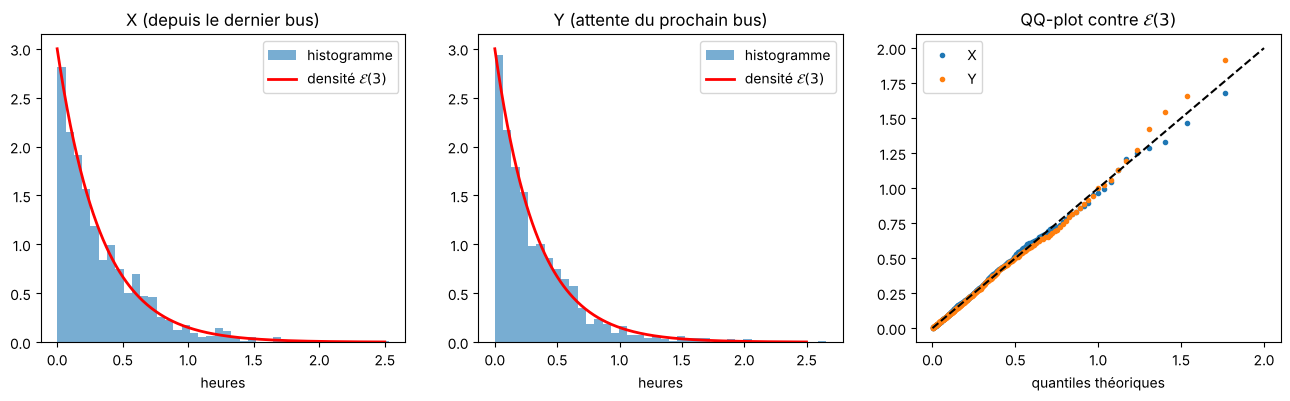

In [11]:
n_jours = 1000
t0 = 6.0        # 14h
Xs, Ys = [], []
for _ in range(n_jours):
    s = simuler_poisson(lam, T)
    avant, apres = s[s <= t0], s[s > t0]
    if len(apres) == 0:
        continue                       # aucun bus après 14h (proba ~1e-4)
    Xs.append(t0 - avant[-1] if len(avant) > 0 else t0)   # si aucun bus depuis 8h : X = 6h
    Ys.append(apres[0] - t0)
Xs, Ys = np.array(Xs), np.array(Ys)

print(f"Jours utilisés : {len(Xs)}")
print(f"Moyenne de X = {Xs.mean()*60:.1f} min,  moyenne de Y = {Ys.mean()*60:.1f} min  (théorie 1/λ = {60/lam:.0f} min)")
print(f"Écart-type X = {Xs.std()*60:.1f} min, écart-type Y = {Ys.std()*60:.1f} min (théorie 1/λ = {60/lam:.0f} min)")
print(f"Corrélation empirique (X, Y) = {np.corrcoef(Xs, Ys)[0,1]:.3f}  (théorie : 0, indépendance)")
print(f"Test de Kolmogorov-Smirnov X ~ Exp(3) : p-valeur = {stats.kstest(Xs, 'expon', args=(0, 1/lam)).pvalue:.3f}")
print(f"Test de Kolmogorov-Smirnov Y ~ Exp(3) : p-valeur = {stats.kstest(Ys, 'expon', args=(0, 1/lam)).pvalue:.3f}")

x = np.linspace(0, 2.5, 300)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, data, nom in zip(ax[:2], [Xs, Ys], ["X (depuis le dernier bus)", "Y (attente du prochain bus)"]):
    a.hist(data, bins=40, density=True, alpha=0.6, label="histogramme")
    a.plot(x, lam*np.exp(-lam*x), 'r', lw=2, label="densité $\\mathcal{E}(3)$")
    a.set_title(nom); a.set_xlabel("heures"); a.legend()
# QQ-plot
q = np.linspace(0.005, 0.995, 200)
ax[2].plot(stats.expon.ppf(q, scale=1/lam), np.quantile(Xs, q), '.', label="X")
ax[2].plot(stats.expon.ppf(q, scale=1/lam), np.quantile(Ys, q), '.', label="Y")
ax[2].plot([0, 2], [0, 2], 'k--'); ax[2].set_title("QQ-plot contre $\\mathcal{E}(3)$")
ax[2].set_xlabel("quantiles théoriques"); ax[2].legend()
plt.show()

Les histogrammes collent aux densités $3e^{-3x}$, les QQ-plots sont alignés sur la diagonale, les moyennes sont proches
de 20 minutes et les p-valeurs des tests de Kolmogorov-Smirnov ne conduisent pas à rejeter l'hypothèse exponentielle :
**$X$ et $Y$ suivent bien (empiriquement) la loi $\mathcal E(\lambda)$, $\lambda=3$**, et ils sont non corrélés.

### Question 4 — Paradoxe de l'autobus

L'intervalle entre les deux bus qui encadrent 14h vaut $L = X + Y$. Comme $X$ et $Y$ sont indépendants de loi
$\mathcal E(\lambda)$, $L\sim\Gamma(2,\lambda)$, de densité $\lambda^2 t e^{-\lambda t}$ et de moyenne
$$\mathbb E[L]=\frac2\lambda = 40 \text{ minutes},$$
alors qu'un intervalle « typique » entre deux bus est $\mathcal E(\lambda)$ de moyenne $1/\lambda=20$ minutes.

**Paradoxe :** l'intervalle dans lequel tombe Alice est en moyenne **deux fois plus long** qu'un intervalle ordinaire,
et son attente moyenne (20 min) est égale à l'intervalle moyen tout entier, et non à la moitié comme l'intuition le suggère.

**Explication (biais par la taille) :** un instant fixé a plus de chances de tomber dans un long intervalle que dans un court.
La densité de l'intervalle observé est proportionnelle à $t\times\lambda e^{-\lambda t}$ (longueur × densité), ce qui
donne exactement $\Gamma(2,\lambda)$.

Intervalle moyen entre deux bus quelconques : 20.0 min (théorie 20 min)
Intervalle moyen contenant 14h (X+Y)       : 40.0 min (théorie 40 min)
Attente moyenne d'Alice E[Y]                : 19.9 min (intuition naïve : 10 min)


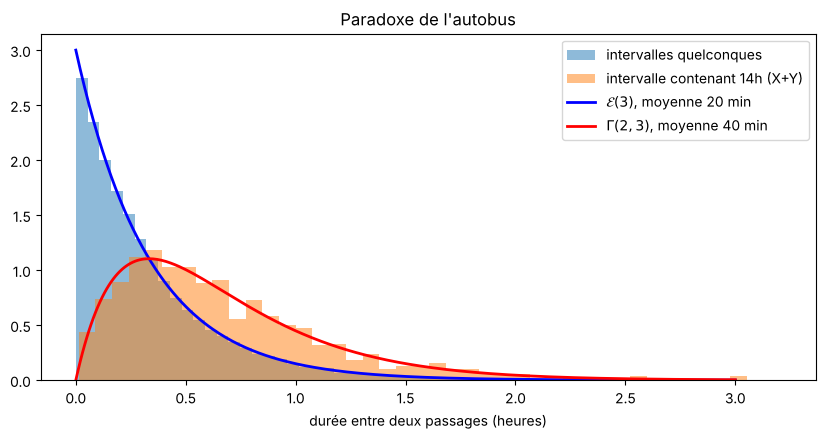

In [12]:
L = Xs + Ys

# Intervalles "ordinaires" : tous les temps entre deux bus consécutifs sur une très longue période
inter = np.diff(simuler_poisson(lam, 10000))

print(f"Intervalle moyen entre deux bus quelconques : {inter.mean()*60:.1f} min (théorie 20 min)")
print(f"Intervalle moyen contenant 14h (X+Y)       : {L.mean()*60:.1f} min (théorie 40 min)")
print(f"Attente moyenne d'Alice E[Y]                : {Ys.mean()*60:.1f} min (intuition naïve : 10 min)")

t = np.linspace(0, 3, 300)
plt.figure(figsize=(10, 4.5))
plt.hist(inter, bins=60, density=True, alpha=0.5, label="intervalles quelconques")
plt.hist(L, bins=40, density=True, alpha=0.5, label="intervalle contenant 14h (X+Y)")
plt.plot(t, lam*np.exp(-lam*t), 'b', lw=2, label="$\\mathcal{E}(3)$, moyenne 20 min")
plt.plot(t, lam**2*t*np.exp(-lam*t), 'r', lw=2, label="$\\Gamma(2,3)$, moyenne 40 min")
plt.xlabel("durée entre deux passages (heures)")
plt.title("Paradoxe de l'autobus"); plt.legend(); plt.show()

Le graphique met en évidence le paradoxe : l'intervalle observé par Alice suit $\Gamma(2,\lambda)$ (moyenne 40 min),
et non $\mathcal E(\lambda)$ (moyenne 20 min). Les intervalles très courts sont rarement « vus » par Alice,
les longs le sont plus souvent.